# Entregable II — Codificación, entrenamiento y selección de variables

**Proyecto:** Predicción de la intención de compra de usuarios en línea mediante
aprendizaje supervisado.  
**Curso:** Modelos y Simulación de Sistemas II — Universidad de Antioquia.  
**Integrantes:** Mateo Upegui Borja, Juan P. Uribe González y Juan D. Rincón Bedoya.

¿Qué familia de modelos ordena mejor las sesiones según su probabilidad de
compra? ¿Conviene retirar las variables que el notebook 01 señaló como débiles?
Para responder, comparamos cinco familias de clasificadores con el mismo
protocolo y las mismas particiones del 01.

El notebook avanza en cuatro pasos. Primero describimos cómo se codifica cada
variable. Después buscamos los hiperparámetros de cada familia con validación
cruzada y elegimos entre los mejores candidatos con la partición de validación.
Por último, medimos cuánto cambia la precisión promedio (AP) al retirar
variables. La partición de prueba no interviene en ninguna de estas decisiones:
la reservamos para la evaluación final del notebook 03.

## 1. Particiones y protocolo

Cargamos las tres particiones que guardó el notebook 01: 7.323 sesiones de
entrenamiento, 2.441 de validación y 2.441 de prueba, estratificadas por
`Revenue`. Cada partición conserva el índice original de las sesiones, así que
cualquier fila se puede rastrear hasta el archivo de partida.

Cada partición cumple un papel distinto:

- **Entrenamiento.** Ajusta los modelos y aloja la validación cruzada de cinco
  pliegues estratificados, con semilla 42, que compara los hiperparámetros.
- **Validación.** Elige entre los tres mejores candidatos de cada familia y,
  después, entre familias.
- **Prueba.** No se usa aquí. El notebook 03 la consulta con las configuraciones
  ya fijadas.

No aplicamos sub ni sobremuestreo. Para compensar el desbalance, en las familias
que lo admiten (regresión logística, Random Forest y SVM), los pesos de clase
balanceados entran en la búsqueda como un hiperparámetro más. Así se ajustan
dentro de la validación cruzada como cualquier otro.

### Métricas

La métrica de selección es la precisión promedio (AP). Ordenamos las sesiones de
mayor a menor puntuación y llamamos $P_n$ y $R_n$ a la precisión y el recall
cuando el umbral es la $n$-ésima puntuación. La AP resume la curva
precisión–recall:

$$\mathrm{AP} = \sum_n (R_n - R_{n-1})\,P_n .$$

Una AP de 1 corresponde a un orden perfecto, con todas las compras por delante
de las sesiones sin compra. Un modelo que ordenara al azar obtendría una AP
cercana a la proporción de compras, alrededor de 0,16 en estas particiones. La
elegimos como métrica principal porque mide la calidad del orden en la clase
minoritaria. La exactitud, en cambio, supera el 84 % con un modelo que siempre
responda «sin compra».

El ROC-AUC es la probabilidad de que una sesión con compra elegida al azar
reciba mayor puntuación que una sin compra, y vale 0,5 al azar. Como también
premia ordenar bien la clase mayoritaria, con clases desbalanceadas puede ser
alto aunque la precisión sea baja. Por eso lo usamos como complemento y no como
criterio de selección.

Las métricas de decisión dependen de un umbral. Con $VP$, $FP$, $VN$ y $FN$ los
verdaderos y falsos positivos y negativos:

$$P = \frac{VP}{VP+FP}, \qquad R = \mathrm{TPR} = \frac{VP}{VP+FN}, \qquad \mathrm{TNR} = \frac{VN}{VN+FP},$$

$$F_1 = \frac{2PR}{P+R}, \qquad \mathrm{BA} = \tfrac{1}{2}\,(\mathrm{TPR} + \mathrm{TNR}).$$

F1 equilibra la precisión y el recall de la clase positiva. La exactitud
balanceada (BA) promedia el recall de las dos clases, de modo que un modelo que
siempre responde «sin compra» obtiene 0,5. Para estas métricas usamos el umbral
nativo de cada modelo: 0,5 sobre la probabilidad y 0 sobre la función de decisión
de SVM. El notebook 03 estudia qué cambia al elegir el umbral en validación.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

from shopytics.presentation import FAMILIAS, VARIANTES, legible
from shopytics.utils import OBJETIVO, PREDICTORAS


def mostrar(tabla):
  """Muestra la tabla con nombres legibles y columnas completas."""
  with pd.option_context("display.max_colwidth", None):
    display(legible(tabla))


ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
datos = ROOT / "data"
eda = ROOT / "resultados" / "variables"
salida = ROOT / "resultados" / "entrenamiento"
cv_dir = salida / "cv"
cv_dir.mkdir(parents=True, exist_ok=True)

particiones = pd.read_pickle(datos / "dataset_particiones.pkl")
train, val = particiones["entrenamiento"], particiones["validacion"]
X_tr, y_tr = train[PREDICTORAS], train[OBJETIVO].astype(int)
X_va, y_va = val[PREDICTORAS], val[OBJETIVO].astype(int)
mostrar(pd.Series({nombre: len(df) for nombre, df in particiones.items()}, name="Sesiones"))

,Sesiones
Entrenamiento,7323
Validación,2441
Prueba,2441


## 2. Codificación de las variables

Cada tipo de variable recibe un tratamiento distinto, que resume la tabla. Todos
los pasos forman parte de un `Pipeline` de scikit-learn, así que se aprenden
solo con los datos de ajuste.

| Variables | Qué miden | Tratamiento |
| --- | --- | --- |
| `Administrative`, `Informational`, `ProductRelated` | Páginas visitadas de cada tipo | Imputación con la mediana, `log1p` opcional y estandarización. |
| `Administrative_Duration`, `Informational_Duration`, `ProductRelated_Duration` | Tiempo en cada tipo de página | Igual que los conteos. El logaritmo comprime la cola derecha y admite ceros. |
| `BounceRates`, `ExitRates`, `PageValues` | Tasas de rebote y salida, y valor de las páginas | Igual que los conteos. La búsqueda decide si se aplica `log1p` a todo el bloque numérico. |
| `Month`, `VisitorType` | Mes y tipo de visitante | Imputación con la moda y codificación one-hot. Una categoría que no apareció en el ajuste queda con ceros en todo el bloque de esa variable. |
| `OperatingSystems`, `Browser`, `Region`, `TrafficType` | Sistema operativo, navegador, región y fuente de tráfico | Igual que las demás nominales. Se guardan como enteros, pero sus valores son códigos sin orden ni distancia, así que no se tratan como números. |
| `Weekend` | Sesión en fin de semana | Pasa directo como indicador 0/1. |
| `SpecialDay` | Cercanía a una fecha especial | Imputación con la mediana y estandarización, sin logaritmo, para conservar su escala ordinal de seis niveles. |
| `Revenue` | Etiqueta de compra | Se separa de los predictores como 0/1. |

Los datos no tienen valores faltantes, pero dejamos la imputación en el pipeline
para que una sesión incompleta no lo rompa.

La celda siguiente guarda una versión ya codificada de las tres particiones, con
`log1p` y el preprocesador ajustado en todo el entrenamiento. El resultado tiene
73 columnas y sirve como referencia de la representación final. La validación
cruzada no la usa. Si los cinco pliegues partieran de una matriz ajustada con
todo el entrenamiento, cada pliegue de evaluación habría influido en las
medianas, las categorías y las escalas, y eso es una fuga de información. Por
eso cada pliegue parte de las columnas originales y ajusta su propio
preprocesador.

In [2]:
from shopytics.models import construir_preprocesador

pre = construir_preprocesador(usar_log=True).fit(X_tr)
columnas = pre.get_feature_names_out()
codificado = {}
for nombre, df in particiones.items():
  codificado[nombre] = {
    "X": pd.DataFrame(pre.transform(df[PREDICTORAS]), index=df.index, columns=columnas),
    "y": df[OBJETIVO].astype(int),
  }

pd.to_pickle(codificado, datos / "dataset_particiones_codificadas.pkl")

mostrar(
  pd.DataFrame({nombre: bloque["X"].shape for nombre, bloque in codificado.items()},
  index=["Sesiones", "Columnas codificadas"]).T
)

,Sesiones,Columnas codificadas
Entrenamiento,7323,73
Validación,2441,73
Prueba,2441,73


## 3. Búsqueda de hiperparámetros

Comparamos cinco familias, una por cada tipo de modelo que exige el proyecto:
regresión logística (paramétrico), k-NN (no paramétrico), Random Forest
(ensamble de árboles), una red neuronal MLP y una SVM. Para cada familia
probamos todas las combinaciones de su malla con validación cruzada de cinco
pliegues y las ordenamos por su AP media fuera de pliegue. En total son 730
configuraciones y 3.650 ajustes.

La primera tabla lista los valores que recorre la malla de cada familia y la
segunda, cuántas configuraciones resultan y qué parámetros quedan fijos. Ambas se
generan desde `shopytics.search.mallas_ampliadas` y `shopytics.models.construir_modelos`,
así que coinciden con lo que se entrena. En Random Forest, `log1p` queda fijo
porque es una transformación monótona y no cambia las divisiones de un árbol. En
SVM, `gamma` solo se explora con el kernel RBF, en una malla aparte, para no
repetir combinaciones con el kernel lineal. Todas las familias usan la semilla 42
cuando el estimador la admite.

Los resultados de cada familia se guardan en `resultados/entrenamiento/cv/`. Con
`REENTRENAR = False`, la celda lee esos archivos en lugar de repetir la
búsqueda; con `True`, la repite completa. Leer los archivos solo es válido si
las particiones, las mallas y el pipeline no cambiaron desde que se generaron.

In [3]:
from sklearn.model_selection import ParameterGrid

from shopytics.models import construir_modelos
from shopytics.presentation import PARAMETROS, valor_legible
from shopytics.search import mallas_ampliadas

FIJOS = {
  "Regresion_logistica": ["solver", "max_iter"],
  "kNN": [],
  "RandomForest": ["n_estimators"],
  "MLP": ["solver", "max_iter", "early_stopping", "validation_fraction", "n_iter_no_change"],
  "SVM": []}


modelos, mallas = mallas_ampliadas()
filas, resumen = [], []

for familia, malla in mallas.items():
  submallas = malla if isinstance(malla, list) else [malla]

  for submalla in submallas:
    nombre = FAMILIAS[familia]

    if len(submallas) > 1:
      nombre += f" ({valor_legible('clf__kernel', submalla['clf__kernel'][0])})"

    for parametro, valores in submalla.items():
      if parametro == "clf__kernel":
          continue

      filas.append({
        "Familia": nombre,
        "Hiperparámetro": PARAMETROS.get(parametro, parametro),
        "Valores": "; ".join(valor_legible(parametro, v) for v in valores)
      })

  estimador = modelos[familia]["clf"].get_params()

  resumen.append({
    "Familia": FAMILIAS[familia],
    "Configuraciones": len(ParameterGrid(malla)),
    "Parámetros fijos": ", ".join(f"{k}={valor_legible(k, estimador[k])}" for k in FIJOS[familia]) or "—"
  })

resumen = pd.DataFrame(resumen).set_index("Familia")
resumen.loc["Total"] = [resumen["Configuraciones"].sum(), ""]
with pd.option_context("display.max_colwidth", None):
  display(pd.DataFrame(filas).set_index(["Familia", "Hiperparámetro"]))
  display(resumen)

Valores
Familia             Hiperparámetro                                                        
Regresión logística log1p                                                           sí; no
                    C                                                0,01; 0,1; 1; 10; 100
                    Pesos de clase                                       ninguno; balanced
k-NN                log1p                                                           sí; no
                    Vecinos (k)                                 5; 15; 31; 45; 61; 81; 101
                    Ponderación                                          uniform; distance
                    Distancia                                          Manhattan; euclídea
Random Forest       log1p                                                               sí
                    Profundidad máxima                     4; 6; 8; 10; 12; 20; sin límite
                    Variables por división                       log2; sqrt; 0,3; 0,5; 0,7
                    Mínimo de sesiones por hoja                               1; 5; 10; 20
                    Pesos de clase                                       ninguno; balanced
MLP                 log1p                                                           sí; no
                    Capas ocultas                (32,); (64,); (128,); (64, 32); (128, 64)
                    alpha                                0,00001; 0,0001; 0,001; 0,01; 0,1
                    Tasa de aprendizaje inicial                0,001; 0,01; 0,03; 0,1; 0,3
SVM (lineal)        log1p                                                           sí; no
                    C                                          0,01; 0,03; 0,1; 1; 10; 100
                    Pesos de clase                                       ninguno; balanced
SVM (RBF)           log1p                                                           sí; no
                    C                                                  0,1; 1; 10; 30; 100
                    gamma                                    scale; 0,001; 0,01; 0,03; 0,1
                    Pesos de clase                                       ninguno; balanced

,Configuraciones,Parámetros fijos
Familia,,
Regresión logística,20,"solver=lbfgs, max_iter=3000"
k-NN,56,—
Random Forest,280,n_estimators=300
MLP,250,"solver=adam, max_iter=500, early_stopping=sí, validation_fraction=0,15, n_iter_no_change=20"
SVM,124,—
Total,730,


In [4]:
import json

from joblib import parallel_backend
from threadpoolctl import threadpool_limits

from shopytics.search import mallas_ampliadas
from shopytics.training import buscar_configuraciones, guardar_registros

REENTRENAR = False
modelos, mallas = mallas_ampliadas()
candidatos = {}

with threadpool_limits(limits=1), parallel_backend("threading", n_jobs=4):
  for familia, modelo in modelos.items():
    archivo = cv_dir / f"{familia}.json"
    if REENTRENAR:
      tabla = buscar_configuraciones(modelo, mallas[familia], X_tr, y_tr, n_jobs=4)
      guardar_registros(tabla, archivo)
    else:
      tabla = pd.DataFrame(json.loads(archivo.read_text(encoding="utf-8")))
    candidatos[familia] = tabla

mostrar(pd.DataFrame([{
  "Familia": FAMILIAS[f], "Configuraciones": len(t),
  "Mayor AP-CV": t.mean_test_score.max()
  } for f, t in candidatos.items()]).set_index("Familia"))

,Configuraciones,Mayor AP-CV
Familia,,
Regresión logística,20,0.689679
k-NN,56,0.720316
Random Forest,280,0.759074
MLP,250,0.741916
SVM,124,0.726585


## 4. Selección en validación

Los tres mejores candidatos de cada familia en validación cruzada pasan a una
segunda ronda. Ajustamos cada uno con todo el entrenamiento, medimos su AP en
validación y nos quedamos con el mejor de cada familia. La ganadora global es la
familia con mayor AP de validación. Guardamos las cinco configuraciones porque
el notebook 03 las evalúa todas y aplica la reducción de dimensión a las dos
primeras.

AP-CV  Desv. CV      AP  \
Modelo              Puesto en CV                             
Regresión logística 1             0.6897    0.0320  0.6841   
                    2             0.6876    0.0317  0.6808   
                    3             0.6863    0.0313  0.6790   
k-NN                1             0.7203    0.0262  0.6966   
                    2             0.7180    0.0271  0.6928   
                    3             0.7172    0.0232  0.7018   
Random Forest       1             0.7591    0.0308  0.7352   
                    2             0.7574    0.0270  0.7392   
                    3             0.7573    0.0234  0.7414   
MLP                 1             0.7419    0.0334  0.7119   
                    2             0.7382    0.0313  0.6747   
                    3             0.7375    0.0342  0.7225   
SVM                 1             0.7266    0.0336  0.7049   
                    2             0.7260    0.0351  0.7054   
                    3             0.7194    0.0322  0.6995   

                                                                                                                                       Configuración  
Modelo              Puesto en CV                                                                                                                      
Regresión logística 1                                                                                        C 0,1; Pesos de clase ninguno; log1p sí  
                    2                                                                                          C 1; Pesos de clase ninguno; log1p sí  
                    3                                                                                         C 10; Pesos de clase ninguno; log1p sí  
k-NN                1                                                             Vecinos (k) 61; Distancia euclídea; Ponderación distance; log1p sí  
                    2                                                             Vecinos (k) 45; Distancia euclídea; Ponderación distance; log1p sí  
                    3                                                             Vecinos (k) 81; Distancia euclídea; Ponderación distance; log1p sí  
Random Forest       1              Pesos de clase ninguno; Profundidad máxima 8; Variables por división 0,3; Mínimo de sesiones por hoja 5; log1p sí  
                    2             Pesos de clase ninguno; Profundidad máxima 6; Variables por división 0,5; Mínimo de sesiones por hoja 10; log1p sí  
                    3             Pesos de clase ninguno; Profundidad máxima 8; Variables por división 0,7; Mínimo de sesiones por hoja 20; log1p sí  
MLP                 1                                                   alpha 0,01; Capas ocultas (128,); Tasa de aprendizaje inicial 0,01; log1p sí  
                    2                                                 alpha 0,0001; Capas ocultas (128,); Tasa de aprendizaje inicial 0,01; log1p sí  
                    3                                                     alpha 0,1; Capas ocultas (64,); Tasa de aprendizaje inicial 0,03; log1p sí  
SVM                 1                                                                 C 10; Pesos de clase ninguno; gamma 0,01; Kernel RBF; log1p sí  
                    2                                                                 C 30; Pesos de clase ninguno; gamma 0,01; Kernel RBF; log1p sí  
                    3                                                                  C 1; Pesos de clase ninguno; gamma 0,03; Kernel RBF; log1p sí

,AP-CV,AP,ROC-AUC,Configuración
Modelo,,,,
Random Forest,0.7573,0.7414,0.9265,"Pesos de clase ninguno; Profundidad máxima 8; Variables por división 0,7; Mínimo de sesiones por hoja 20; log1p sí"
MLP,0.7375,0.7225,0.9242,"alpha 0,1; Capas ocultas (64,); Tasa de aprendizaje inicial 0,03; log1p sí"
SVM,0.7260,0.7054,0.9001,"C 30; Pesos de clase ninguno; gamma 0,01; Kernel RBF; log1p sí"
k-NN,0.7172,0.7018,0.9124,Vecinos (k) 81; Distancia euclídea; Ponderación distance; log1p sí
Regresión logística,0.6897,0.6841,0.9123,"C 0,1; Pesos de clase ninguno; log1p sí"


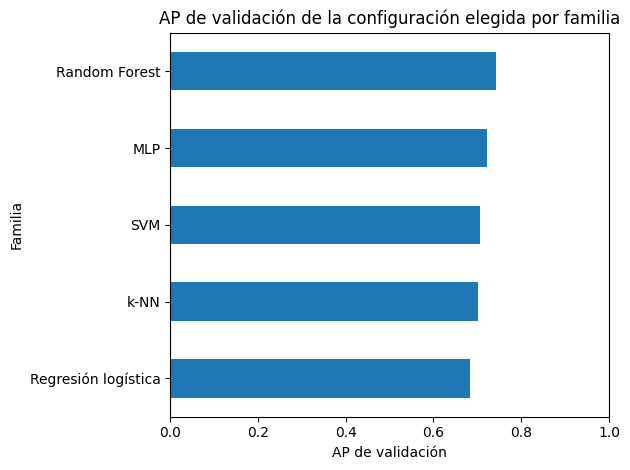

In [5]:
import matplotlib.pyplot as plt

from shopytics.training import validar_finalistas
from shopytics.utils import SEMILLA

# Segunda ronda: los tres mejores de CV de cada familia, medidos en validación.
with threadpool_limits(limits=1):
  finalistas = pd.concat(
    [validar_finalistas(modelo, candidatos[familia], X_tr, y_tr, X_va, y_va).assign(modelo=familia) for familia, modelo in modelos.items()],
    ignore_index=True,
  )

mejores = finalistas.sort_values("AP", ascending=False).drop_duplicates("modelo")
primero = mejores.iloc[0]

ganador = {
  "modelo": primero.modelo,
  "params": primero.params,
  "AP_validacion": primero.AP,
  "AP_CV": primero.AP_CV,
  "semilla": SEMILLA,
  "predictores": PREDICTORAS,
  "criterio": "Mayor AP de validación entre los tres finalistas por AP-CV de cada familia",
}

guardar_registros(finalistas, salida / "finalistas.json")
guardar_registros(mejores, salida / "mejores_configuraciones.json")

(salida / "ganador.json").write_text(
  json.dumps(ganador,
  indent=2,
  ensure_ascii=False) + "\n",
  encoding="utf-8"
)

mostrar(finalistas.set_index(["modelo", "rango_cv"])[["AP_CV", "std_CV", "AP", "params"]].round(4))
mostrar(mejores.set_index("modelo")[["AP_CV", "AP", "ROC_AUC", "params"]].round(4))

ax = (mejores.assign(modelo=mejores.modelo.map(FAMILIAS))
  .sort_values("AP")
  .plot.barh(x="modelo", y="AP", legend=False))

ax.set(
  xlabel="AP de validación",
  ylabel="Familia", xlim=(0, 1),
  title="AP de validación de la configuración elegida por familia"
)

plt.tight_layout()
plt.show()

Random Forest gana con una AP de validación de 0,7414, seguido de MLP (0,7225),
SVM (0,7054), k-NN (0,7018) y regresión logística (0,6841). El orden entre
familias es el mismo que en validación cruzada. Las cuatro familias que exploran
`log1p` lo eligen, y ninguna de las tres que admiten pesos de clase los usa.

Dentro de cada familia, la segunda ronda sí cambia la elección. Solo en
regresión logística gana el primer candidato de la validación cruzada. En Random
Forest, la configuración elegida era la tercera en validación cruzada (0,7573
frente a 0,7591 de la primera), pero obtiene la mayor AP de validación de las
tres (0,7414 frente a 0,7352 y 0,7392). Lo mismo pasa en MLP y k-NN. Las
diferencias entre finalistas de una misma familia son mucho menores que la
desviación entre pliegues, de unos 0,03. Por eso la validación funciona aquí
como desempate entre candidatos prácticamente equivalentes, no como una mejora
clara.

## 5. Ablación de variables

El notebook 01 marcó seis variables con AUC individual menor que 0,55 y dos
pares de variables muy correlacionadas. Una variable débil por sí sola todavía
puede aportar en combinación con otras, así que la única forma de decidir es
retirarla y medir. Hacemos esa prueba con las dos mejores familias, Random
Forest y MLP, y mantenemos fijos sus hiperparámetros seleccionados. Comparamos
tres variantes:

- **Completo.** Los 17 predictores.
- **Sin candidatas.** Sin las seis variables marcadas como «eliminar o
  combinar»: `Weekend`, `Region`, `Browser`, `VisitorType`, `SpecialDay` y
  `OperatingSystems`.
- **Sin redundantes.** Sin un miembro de cada par correlacionado. Del par de
  páginas de producto conservamos el conteo, más fácil de interpretar, y
  retiramos `ProductRelated_Duration`. Del par de tasas conservamos `ExitRates`,
  que tiene mayor AUC individual, y retiramos `BounceRates`.

Las tres variantes usan los mismos pliegues y la misma partición de validación.
La comparación principal es el cambio de AP en validación respecto a la variante
completa de la misma familia: un valor positivo indica que el modelo obtuvo más
AP sin esas variables. Las candidatas se eligieron con todo el entrenamiento,
así que el AP de validación cruzada de esta sección no es una estimación
independiente; el de validación sí lo es.

Variables retiradas  \
Modelo        Variante                                                                               
Random Forest Completo                                                                               
              Sin candidatas   Weekend, Region, Browser, VisitorType, SpecialDay, OperatingSystems   
              Sin redundantes                                 ProductRelated_Duration, BounceRates   
MLP           Completo                                                                               
              Sin candidatas   Weekend, Region, Browser, VisitorType, SpecialDay, OperatingSystems   
              Sin redundantes                                 ProductRelated_Duration, BounceRates   

                                AP-CV      AP  ΔAP validación  
Modelo        Variante                                         
Random Forest Completo         0.7573  0.7414          0.0000  
              Sin candidatas   0.7566  0.7422          0.0008  
              Sin redundantes  0.7485  0.7348         -0.0066  
MLP           Completo         0.7375  0.7225          0.0000  
              Sin candidatas   0.7413  0.7414          0.0190  
              Sin redundantes  0.7359  0.7250          0.0026

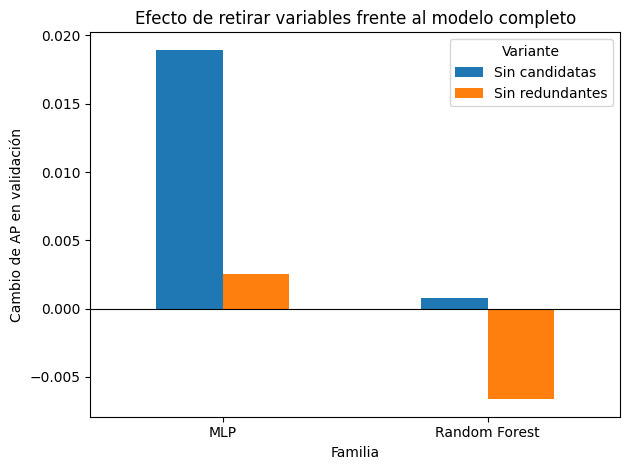

In [6]:
from shopytics.training import evaluar_ablacion

ranking = pd.read_json(eda / "analisis_variables.json").set_index("variable")
pares = pd.read_json(eda / "redundancia_numericas.json")


def variable_a_retirar(par):
  """Del par de producto retira la duración; de los demás, la de menor AUC."""
  variables = [par.variable_1, par.variable_2]
  if set(variables) == {"ProductRelated", "ProductRelated_Duration"}:
    return "ProductRelated_Duration"
  return ranking.loc[variables, "auc_univariado"].idxmin()


candidatas = (ranking.query("recomendacion == 'eliminar o combinar'")
  .sort_values("auc_univariado").index.tolist())

variantes = {
    "completo": [],
    "sin_candidatas": candidatas,
    "sin_redundantes": [variable_a_retirar(par) for par in pares.itertuples()],
}

configuraciones = mejores.set_index("modelo").loc[["RandomForest", "MLP"], "params"].to_dict()

with threadpool_limits(limits=1):
  ablacion = evaluar_ablacion(configuraciones, variantes, X_tr, y_tr, X_va, y_va)
guardar_registros(ablacion, salida / "ablacion.json")

mostrar(ablacion.assign(excluidas=ablacion.excluidas.str.join(", "))
  .set_index(["modelo", "variante"])[["excluidas", "AP_CV", "AP", "delta_AP"]].round(4))

cambios = (ablacion.query("variante != 'completo'")
  .pivot(index="modelo", columns="variante", values="delta_AP")
  .rename(index=FAMILIAS, columns=VARIANTES))

ax = cambios.plot.bar(rot=0)
ax.axhline(0, color="black", linewidth=0.8)

ax.set(
  xlabel="Familia",
  ylabel="Cambio de AP en validación",
  title="Efecto de retirar variables frente al modelo completo"
)

ax.legend(title="Variante")
plt.tight_layout()
plt.show()

## 6. Conclusiones

La tabla resume, para cada familia y variante, cuántos predictores quedan y
cuánto cambia el AP en validación y en validación cruzada frente al modelo
completo.

In [7]:
ap_cv_completo = ablacion.query("variante == 'completo'").set_index("modelo").AP_CV

resumen_ablacion = (
  ablacion.query("variante != 'completo'")
  .assign(
    predictores=lambda t: len(PREDICTORAS) - t.excluidas.str.len(),
    delta_AP_CV=lambda t: t.AP_CV - t.modelo.map(ap_cv_completo)
  ).set_index(["modelo", "variante"])[["predictores", "delta_AP", "delta_AP_CV"]]
)
mostrar(resumen_ablacion.round(4))

Predictores  ΔAP validación  ΔAP-CV
Modelo        Variante                                            
Random Forest Sin candidatas            11          0.0008 -0.0007
              Sin redundantes           15         -0.0066 -0.0088
MLP           Sin candidatas            11          0.0190  0.0038
              Sin redundantes           15          0.0026 -0.0017

Retirar las seis candidatas no empeora ninguno de los dos modelos. En Random
Forest, el AP de validación sube 0,0008 y el de validación cruzada baja 0,0007;
ambos cambios son mucho menores que la desviación entre pliegues. En MLP, el AP
de validación sube 0,0190, pero en validación cruzada la mejora es de solo
0,0038, así que no la tomamos como una ganancia real. Las seis variables se
pueden retirar sin perder capacidad de ordenar las sesiones, y el modelo queda
con 11 predictores.

Retirar las redundantes, en cambio, no ayuda. Random Forest pierde 0,0066 de AP
en validación y 0,0088 en validación cruzada. MLP gana 0,0026 en validación pero
pierde 0,0017 en validación cruzada. Aunque las variables de cada par están muy
correlacionadas, cada una aporta algo que la otra no recoge, así que conviene
conservarlas.

La familia ganadora se eligió con los 17 predictores, y así la evalúa el
notebook 03. Guardamos la ablación aparte para no mezclar dos preguntas: qué
clasificador elegir y si conviene simplificar su entrada.